In [23]:
import os
main_pth = '/users/kduecker/hnn-tuning'
pth_mod = os.path.join(main_pth, 'local_hnn/hnn_core/mod')
pth_rslts = os.path.join(main_pth, 'new_cells_dev/gen_algo/results_l23')
os.makedirs(pth_rslts, exist_ok=True)
pth_data = os.path.join(main_pth, 'data/l23')
figpth = os.path.join(main_pth, 'new_cells_dev/figures/l23_tuning/')

from copy import deepcopy
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import matplotlib as mpl
import sys
sys.path.append(os.path.join(main_pth, 'new_cells_dev/utils'))
from iascone_mechs_utils import Mechs, get_iascone_params
from cell_builder_utils import l2_params, _get_dends, _get_pyr_soma, Cell
import cell_builder_utils
import numpy as np
import pickle
import neuron
from neuron import h
from neuron.units import ms, mV
from l23_optimize_slurm import reconstruct_params, _exp_func
from scipy.optimize import curve_fit
import scipy.signal as signal

from matplotlib import colormaps

cmap = colormaps['viridis']
cols_dist = cmap.colors[0:len(cmap.colors):20]

from l23_optimize_slurm import reconstruct_params


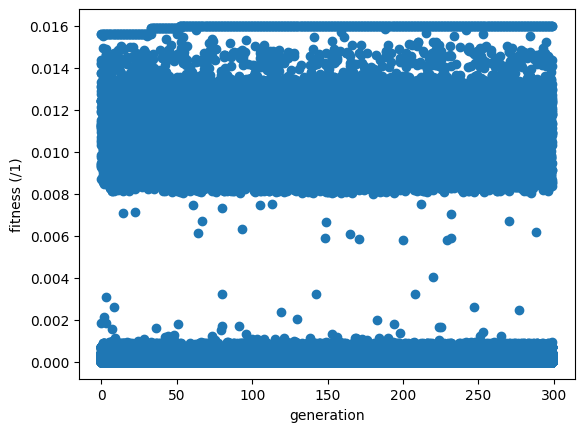

In [24]:
fitn = np.load(f'{pth_rslts}/generation_fitness.npy')

fig, ax = plt.subplots()
ax.plot(np.max(fitn, axis=1), 'o', color='tab:blue');
ax.plot(fitn, 'o', color='tab:blue');#
ax.set_ylabel('fitness (/1)')
ax.set_xlabel('generation')

fig.savefig(f'{figpth}fitness_gen.png')

In [3]:
with open(f'{pth_rslts}/best_sol.pkl', 'rb') as f:
    best_params, fitness, x = pickle.load(f)

In [6]:
x

0

In [9]:
model_params = reconstruct_params(best_params)
model_params

{'soma': {'NaTs2_t_32d': 1.5,
  'SKv3_1': 0.4,
  'Nap_Et2': 0.004489289084814533,
  'Ca_HVA': 0.005,
  'Ca_LVAst': 1e-05,
  'pas': 2.5e-05,
  'Ih': 0.005,
  'SK_E2': 0.005,
  'Im': 0.05},
 'basal': {'NaTs2_t_32d': 0.01,
  'SKv3_1': 0.0001,
  'Ih': 0.01,
  'pas': 2.9499221423262673e-05},
 'dend': {'NaTa_t_32d': 0.005,
  'SKv3_1': 0.05,
  'Ca_HVA': 1e-05,
  'Ca_LVAst': 0.005,
  'pas': 0.00011111111111111112,
  'SK_E2': 1e-07,
  'Ih': 1e-05,
  'Im': 0.001,
  'CaDynamics_E2': {'decay': 60.0, 'gamma': 0.1}},
 'e_pas': -90.0,
 'passive_params': {'L2Pyr_soma_cm': 0.5,
  'L2Pyr_soma_Ra': 70.0,
  'L2Pyr_dend_cm': 0.5,
  'L2Pyr_dend_Ra': 70.0}}

In [10]:
# get paramaters
section_params, end_pts, cell_tree = l2_params()

# build sections
section_names = list(end_pts.keys())

v_init = {'all': -65}

# replace cm and Ra
for p_key, p_val in model_params['passive_params'].items():
    for key in section_params:
        if p_key in key:
            section_params[key] = p_val

sections = _get_dends(section_params, 'L2Pyr', section_names, end_pts, v_init=v_init)
sections['soma'] = _get_pyr_soma(section_params, 'L2Pyr', end_pts['soma'], v_init=v_init['all'])

mech_class = Mechs(pth_mod)

l2pyr= Cell(sections, cell_tree, cell_type = 'L2_pyramidal', gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, model_params)

'soma': -66.74869599011409,
'basal_1': -66.52871241592328,
'basal_2': -65.89807360724394,
'basal_3': -65.89807360724394,
'apical_oblique': -66.36962715151402,
'apical_trunk': -66.88852953462461,
'apical_1': -68.09007932942009,
'apical_tuft': -69.19198082221706,


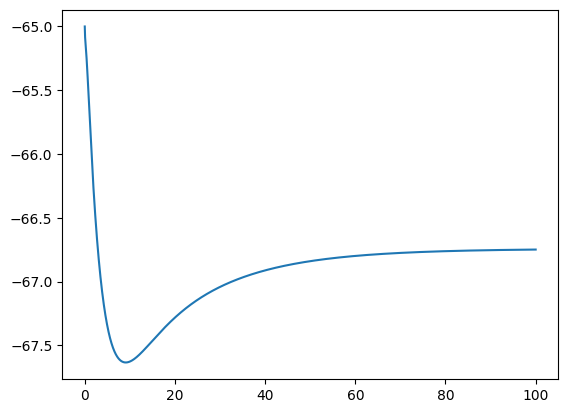

In [13]:
# RMP

l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramidal', gid=0)
l2pyr.build()

l2pyr = mech_class.add_mechs(l2pyr, model_params)
distance = []
h.distance(sec = l2pyr._nrn_sections['soma'])
section_names = ['soma', 'basal_1','basal_2', 'basal_3', 'apical_oblique', 'apical_trunk','apical_1', 'apical_tuft']
sec_seg = []

v_s = []
for s, section in enumerate(section_names):
    v_s.append(h.Vector().record(l2pyr._nrn_sections[section](0.5)._ref_v))

t = h.Vector().record(h._ref_t)
h.celsius = 37
h.finitialize(-65)
h.continuerun(100 * ms)
h.dt = 0.025
v_init = {}
for s, section in enumerate(section_names):
    v = v_s[s].as_numpy()
    v_init[section] = v[-1]
    print(f"'{section}': {v[-1]},")
    
plt.plot(t, v_s[0])


sections = _get_dends(section_params, 'L2Pyr', section_names, end_pts, v_init=v_init)
sections['soma'] = _get_pyr_soma(section_params, 'L2Pyr', end_pts['soma'], v_init=v_init['soma'])

In [14]:
def fig_voltage(model, clamp_current, l_stim=100):
    
    section_names = ['apical_tuft', 'apical_1', 'apical_trunk', 'basal_1', 'basal_2', 'basal_3', 'apical_oblique', 'soma']

    voltg = [None]*len(section_names)
    for i, section in enumerate(section_names):
        voltg[i] = h.Vector().record(model._nrn_sections[section](0.5)._ref_v)

    t = h.Vector().record(h._ref_t)

    h.celsius = 37
    h.finitialize()
    h.continuerun(l_stim * ms)

    fig, ax = plt.subplots(2,1, figsize=(16,20), height_ratios=[0.25, 1], sharex=True)

    for c in clamp_current:
        ax[0].plot(t,c, color='k')

    yticks_v = []
    yticklabels_v = []

    cv = 0
    for i,section in enumerate(section_names):
        
        ax[1].plot(t,voltg[i] + cv)

        yticks_v.append(-75+cv)
        yticks_v.append(50+cv)

        yticklabels_v.append(str(np.round(-75)))
        yticklabels_v.append(str(np.round(50)))

        cv -= 200

    ax[1].set_yticks(yticks_v)
    ax[1].set_yticklabels(yticklabels_v)
    ax[1].set_ylabel('voltage $\mu V$')
    ax[1].set_xlabel('time (ms)')
    ax[1].legend(section_names)

    return fig

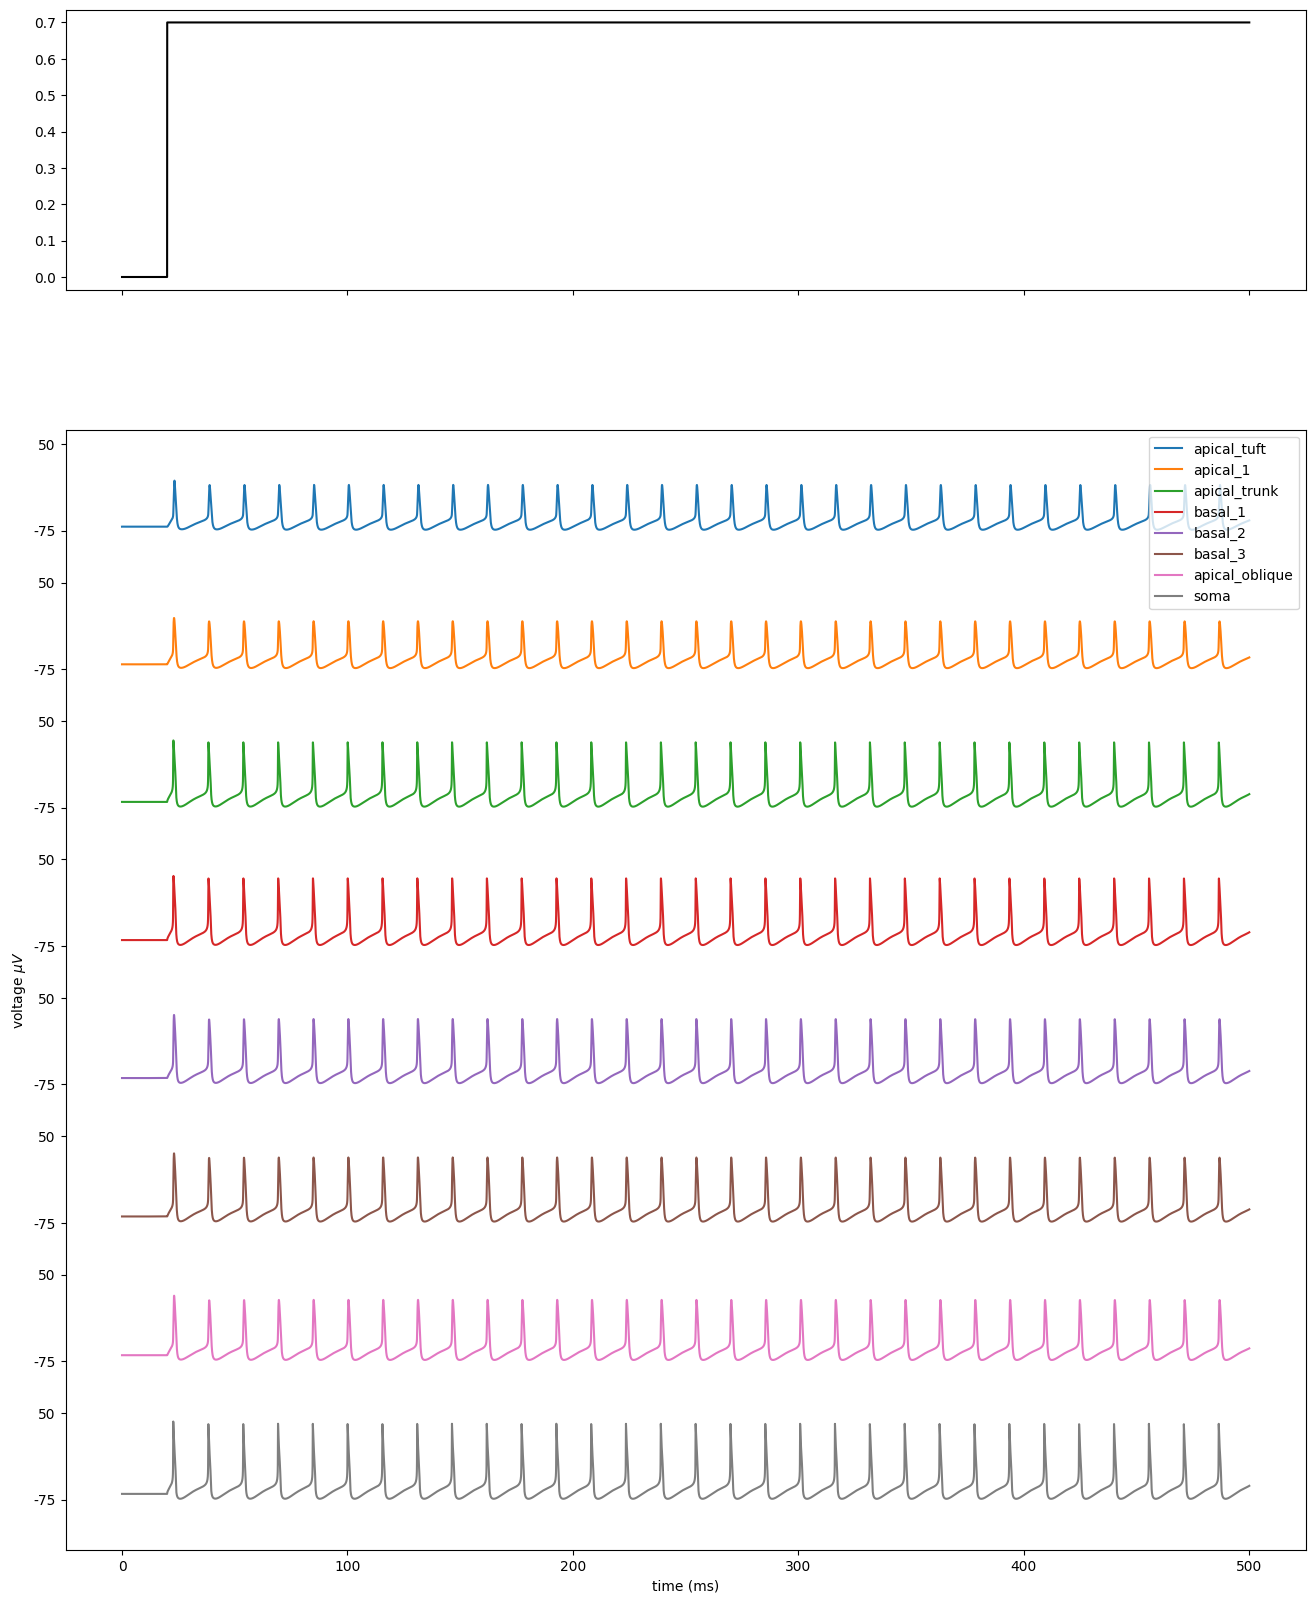

In [15]:
l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)

l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, model_params)

num_pulse = 1
stim = [None]*num_pulse
clamp_current = [None]*num_pulse
for i in range(num_pulse):
    stim[i] = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim[i].delay = 20+(10*i)
    stim[i].dur = 1000
    stim[i].amp = .7
    clamp_current[i] = h.Vector().record(stim[i]._ref_i)

fig = fig_voltage(l2pyr, clamp_current, l_stim=500)

In [17]:
v_init

{'soma': -66.74869599011409,
 'basal_1': -66.52871241592328,
 'basal_2': -65.89807360724394,
 'basal_3': -65.89807360724394,
 'apical_oblique': -66.36962715151402,
 'apical_trunk': -66.88852953462461,
 'apical_1': -68.09007932942009,
 'apical_tuft': -69.19198082221706}

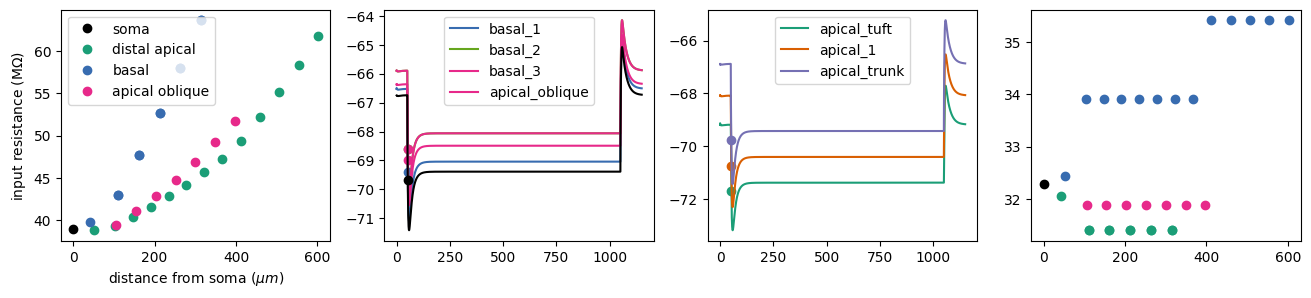

In [18]:
# input resistance
section_names = ['apical_tuft', 'apical_1', 'apical_trunk', 'basal_1', 'basal_2', 'basal_3', 'apical_oblique', 'soma']
inp_res_apcl = []
inp_res_basal = []
inp_res_soma = []
inp_res_oblq = []

distance_apcl = []
distance_basal = []
distance_oblq = []
soma = []

del l2pyr 
h('forall delete_section()')

l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramidal', gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, model_params)

h.distance(sec = l2pyr._nrn_sections['soma'])
for s, section in enumerate(section_names):
    for i, seg in enumerate(l2pyr._nrn_sections[section]):
        
        impedance = h.Impedance()
        h.celsius = 37
        h.finitialize()
        impedance.loc(seg.x, sec=l2pyr._nrn_sections[section])
        impedance.compute(0)

        if 'basal' in section:
            inp_res_basal.append(impedance.input(l2pyr._nrn_sections[section](seg.x)))
            distance_basal.append(h.distance(seg))
        elif section == 'apical_oblique':
            inp_res_oblq.append(impedance.input(l2pyr._nrn_sections[section](seg.x)))
            distance_oblq.append(h.distance(seg))
        elif 'apical' in section:
            inp_res_apcl.append(impedance.input(l2pyr._nrn_sections[section](seg.x)))
            distance_apcl.append(h.distance(seg))

        elif section == 'soma':
            inp_res_soma.append(impedance.input(l2pyr._nrn_sections[section](seg.x)))

cols_apcl = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
cols_basal = np.array(([56,108,176], [102,166,30], [231,41,138], [231,41,138]))/255

fig, ax = plt.subplots(1,4, figsize=(16, 3))

ax[0].plot(0, inp_res_soma, 'o', color='k', label='soma')
ax[0].plot(distance_apcl, inp_res_apcl, 'o', color=cols_apcl[0], label='distal apical')
ax[0].plot(distance_basal, inp_res_basal, 'o', color=cols_basal[0], label='basal')
ax[0].plot(distance_oblq, inp_res_oblq, 'o', color=cols_basal[2], label='apical oblique')
ax[0].set_xlabel('distance from soma ($\mu m$)')
ax[0].set_ylabel('input resistance (M$\Omega$)')

section_names = ['apical_tuft', 'apical_1', 'apical_trunk', 'basal_1', 'basal_2', 'basal_3', 'apical_oblique', 'soma']

voltg = [None]*len(section_names)
tau_m_apcl_mnl = []
tau_m_basal_mnl = []
tau_m_soma_mnl = []
tau_m_oblq_mnl = []

tau_m_apcl_cf = []
tau_m_basal_cf = []
tau_m_soma_cf = []
tau_m_oblq_cf = []

# Goal: tau_m = 17 ms
cb = 0
ca = 0
for s, section in enumerate(section_names):
    for i, seg in enumerate(l2pyr._nrn_sections[section]):

        l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramidal', gid=0)
        l2pyr.build()
        l2pyr = mech_class.add_mechs(l2pyr, model_params)
        h.distance(sec = l2pyr._nrn_sections['soma'])

        stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
        stim.delay = 50
        stim.dur = 1000
        stim.amp = -0.15

        voltg[i] = h.Vector().record(l2pyr._nrn_sections[section](0.5)._ref_v)

        t = h.Vector().record(h._ref_t)

        h.celsius = 37
        h.finitialize()
        h.continuerun(1150 * ms)

        v_np = voltg[i].as_numpy()
        t_np = t.as_numpy()
        start_idx = np.where(t_np > stim.delay)[0][0]

        # maximum amplitude
        max_ampl = v_np[start_idx]  - np.min(v_np)
        frac_ampl = v_np[start_idx]  - max_ampl * 0.63                 # 63% of amplitude
        thresh_tp = np.argmin(np.abs(v_np[:np.argmin(v_np)] - frac_ampl))       # time point when threshold is reached

        

        start_idx = np.where(t_np > stim.delay)[0][0]
        end_idx = np.where(t_np > stim.delay + stim.dur*0.9)[0][0]      # steady state, see https://pmc.ncbi.nlm.nih.gov/articles/PMC2775376/

        t_rise = t_np[start_idx:end_idx] - stim.delay # Time starting at 0
        v_rise = v_np[start_idx:end_idx]

        delta_v = np.mean(v_rise) - np.mean(v[:start_idx])
        # Fit the exponential function to the data
        popt, pcov = curve_fit(_exp_func, t_rise, v_rise, p0=[10, abs(delta_v), v_rise[0]])
        tau_m_fitted = popt[0] # This is the fitted time constant in ms

        
        if section == 'soma':
            tau_m_soma_mnl.append(t_np[thresh_tp] - t_np[start_idx])  # time constant
            tau_m_soma_cf.append(tau_m_fitted)
        elif 'basal' in section:
            tau_m_basal_mnl.append(t_np[thresh_tp] - t_np[start_idx])
            tau_m_basal_cf.append(tau_m_fitted)
        elif section == 'apical_oblique':
            tau_m_oblq_mnl.append(t_np[thresh_tp] - t_np[start_idx])
            tau_m_oblq_cf.append(tau_m_fitted)
        elif 'apical' in section:
            tau_m_apcl_mnl.append(t_np[thresh_tp] - t_np[start_idx])
            tau_m_apcl_cf.append(tau_m_fitted)

    if section == 'soma':
        ax[1].plot(t, voltg[i], color='k')
        ax[1].plot(t_np[thresh_tp], v_np[thresh_tp], 'o', color='k')
    elif section == 'apical_oblique' or 'basal' in section:
        ax[1].plot(t, voltg[i], color=cols_basal[cb], label=section)
        ax[1].plot(t_np[thresh_tp], v_np[thresh_tp], 'o', color=cols_basal[cb])
        cb+=1
    else:
        ax[2].plot(t, voltg[i], color=cols_apcl[ca], label=section)
        ax[2].plot(t_np[thresh_tp], v_np[thresh_tp], 'o', color=cols_apcl[ca])
        ca+=1

ax[3].plot(0, tau_m_soma_cf, 'o', color='k')
ax[3].plot(distance_basal, tau_m_basal_cf, 'o', color=cols_apcl[0])
ax[3].plot(distance_apcl, tau_m_apcl_cf, 'o', color=cols_basal[0])
ax[3].plot(distance_oblq, tau_m_oblq_cf, 'o', color=cols_basal[2])

ax[1].legend()
ax[2].legend()
ax[0].legend()

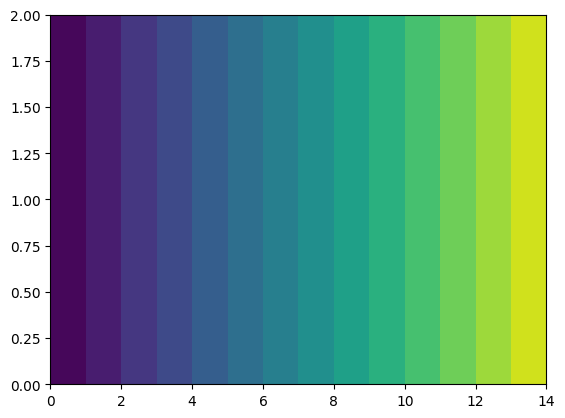

In [19]:
section_names = ['soma', 'apical_trunk', 'apical_1', 'apical_tuft']
del l2pyr
h('forall delete_section()')

l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramidal', gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, model_params)


distance = []
h.distance(sec = l2pyr._nrn_sections['soma'])
for section in section_names:
    for seg in l2pyr._nrn_sections[section]:
        distance.append(h.distance(seg.x, sec=seg.sec))

im = plt.pcolormesh(np.tile(np.array(distance),(2,1)), cmap='viridis', vmin=0, vmax=650)

In [20]:
def attenuation_from_section(ref_sect, amp, stim_dur, ax):


    l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramidal', gid=0)
    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, model_params)
    h.distance(sec = l2pyr._nrn_sections[ref_sect])
    
    
    stim = h.IClamp(l2pyr._nrn_sections[ref_sect](0.5))
    stim.delay = 20
    stim.dur = stim_dur
    stim.amp = amp

    t = h.Vector().record(h._ref_t)
    
    ref_voltg = h.Vector().record(l2pyr._nrn_sections[ref_sect](0.5)._ref_v)
    
    sections_minus_ref = [section for section in section_names if section != ref_sect]

    upstroke = []
    dend_voltg = []
    
    distance = []
    
    for s, section in enumerate(sections_minus_ref):
        for sg, seg in enumerate(l2pyr._nrn_sections[section]):

            dend_voltg.append(h.Vector().record(l2pyr._nrn_sections[section](seg.x)._ref_v))

            distance.append(h.distance(seg))

    h.celsius = 37
    h.finitialize()
    h.continuerun(1100 * ms)

    ax.plot(t, ref_voltg, color='k')
    
    t_np = t.as_numpy()
    amp_ref = []
    amp_dend = []
    i = 0
    for s, section in enumerate(sections_minus_ref):
        for sg, seg in enumerate(l2pyr._nrn_sections[section]):
            # low-pass filter 5KHz like in Gidon et al.,
            sfreq = 1000/np.diff(t.as_numpy())[0]
            b, a = signal.butter(0, 5000, btype='low', analog=False, fs=sfreq)

            v = dend_voltg[i].as_numpy()
            d_filt = signal.lfilter(b, a, v)
            r_filt = signal.lfilter(b, a, ref_voltg.as_numpy())

            if amp > 0:  
                # upstroke per ms (Gidon et al., 2020 Fig S5 A)
                upstroke.append(np.max(np.diff(d_filt))/np.diff(t_np)[0])     

                amp_ref.append(np.max(r_filt) - np.min(r_filt))
                amp_dend.append(np.max(d_filt) - np.min(d_filt))

            elif amp     < 0:
                start_idx = np.argmin(np.abs(t_np - (stim.delay+800))) # Gidon 2020
                end_idx = np.argmin(np.abs(t_np - (stim.delay+1000))) # Gooch, 2022

                amp_ref.append(np.mean(r_filt[start_idx:end_idx]))
                amp_dend.append(np.mean(d_filt[start_idx:end_idx]))

            
            ax.plot(t_np,v, color=cols_dist[i])
            i += 1
    
    cb = plt.colorbar(im, ax=ax, orientation='horizontal', label=f'distance from {ref_sect} ($\mu m$)', shrink=0.5)
    ax.set_ylabel('membrane potential (mV)')
    ax.set_xlabel('time (ms)')
    # calculate attenuation
    atten = np.array(amp_dend) / np.array(amp_ref) * 100

    return atten, distance, upstroke

/tmp/ipykernel_683659/1018209620.py:71: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 1 Axes> than <Figure size 1600x300 with 6 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(im, ax=ax, orientation='horizontal', label=f'distance from {ref_sect} ($\mu m$)', shrink=0.5)
/tmp/ipykernel_683659/1018209620.py:71: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 1 Axes> than <Figure size 1600x300 with 7 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(im, ax=ax, orientation='horizontal', label=f'distance from {ref_sect} ($\mu m$)', shrink=0.5)


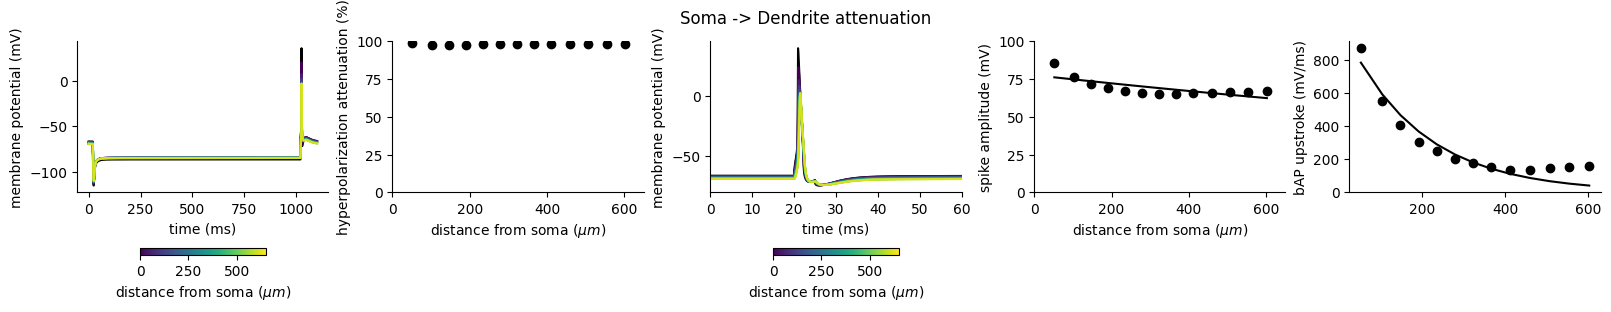

In [25]:
def exp_decay(x, lambda_val, A):
    return A * np.exp(-x / lambda_val)


fig, ax = plt.subplots(1,5, figsize=(16,3), constrained_layout=True)

# soma to dendrite attenuation
section_names = ['soma', 'apical_trunk', 'apical_1', 'apical_tuft']
ref_sect = 'soma'

# hyperpolarization attenuation
hyperpol_atten, elec_sep, _ = attenuation_from_section(ref_sect, amp=-2, stim_dur=1000, ax=ax[0])
popt, pcov = curve_fit(exp_decay, np.array(elec_sep), np.array(hyperpol_atten), p0=[100, hyperpol_atten[0] ])
lambda_hyperpol = popt[0]

# ax[0].set_ylim([-150, -40])
# ax[0].set_yticks([-150, -100, -50])
ax[1].plot(elec_sep, hyperpol_atten, 'o', color='k')
ax[1].set_xlabel('distance from soma ($\mu m$)')
ax[1].set_ylabel('hyperpolarization attenuation (%)')
#ax[1].set_ylim([0, 100])
ax[1].set_yticks(np.arange(0, 101, 25))

ax[1].set_xlim([0, 650])

# spike attenuation
spike_amp, _, upstroke = attenuation_from_section(ref_sect, amp=2, stim_dur=5,ax=ax[2])

ax[3].plot(elec_sep, spike_amp, 'o', color='k')
popt, pcov = curve_fit(exp_decay, np.array(elec_sep), np.array(spike_amp), p0=[100, spike_amp[0] ])
lambda_spike_amp = popt[0]
ax[3].plot(elec_sep, exp_decay(np.array(elec_sep), *popt), color='k')

ax[3].set_xlabel('distance from soma ($\mu m$)')
ax[3].set_ylabel('spike amplitude (mV)')
#ax[3].set_ylim([0, 100])
ax[3].set_xlim([0, 650])

# ax[2].set_ylim([-70, 40])
# ax[2].set_yticks([-70, 0, 40])
ax[2].set_xlim([0, 60])
ax[3].set_yticks(np.arange(0, 101, 25))


ax[4].plot(elec_sep, upstroke, 'o', color='k')
popt, pcov = curve_fit(exp_decay, np.array(elec_sep), np.array(upstroke), p0=[100, upstroke[0] ])
ax[4].plot(elec_sep, exp_decay(np.array(elec_sep), *popt), color='k')
lambda_upstroke = popt[0]
#ax[4].set_ylim([0, 250])
ax[4].set_ylabel('bAP upstroke (mV/ms)')

fig.suptitle('Soma -> Dendrite attenuation')

for a in ax:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)

fig.savefig(f'{figpth}attenuation_soma.png')